# 07 - Post-Test Analysis

Notebook ini **post-hoc**. Model, fitur, threshold, dan config **tidak diubah**.
Evaluasi test sudah dilakukan di notebook 06. Di sini hanya dilakukan analisis
berpasangan dan per-bulan untuk memahami hasil test.

B dihitung ulang dengan fit identik pada train (tanpa tuning), tanpa mengubah
artefak.

In [1]:
from pathlib import Path
import sys

import joblib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import siapkan_fitur, tambah_volume_lag

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

metadata = json.loads((ROOT / "artifacts" / "metadata.json").read_text(encoding="utf-8"))
model_final = joblib.load(ROOT / "artifacts" / "model.joblib")

data = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["tanggal_pickup"])
train = data.loc[data["tanggal_pickup"] <= "2025-12-31"].copy()
valid = data.loc[data["tanggal_pickup"].between("2026-01-01", "2026-03-31")].copy()
test = data.loc[data["tanggal_pickup"].between("2026-04-01", "2026-06-30")].copy()
del data

referensi_valid = pd.concat([train, valid], ignore_index=True)
valid_lag = tambah_volume_lag(valid, referensi_valid)
X_valid_C = siapkan_fitur(valid_lag, metadata)
prob_C_valid = model_final.predict_proba(X_valid_C)[:, 1]

NUM_B = ["jam_pickup", "jarak_km", "jumlah_transit", "janji_hari", "berat_kg"]
CAT_B = ["kota_tujuan", "layanan", "metode_bayar", "cuaca_saat_pickup"]
prep_B = ColumnTransformer(
    [
        ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), NUM_B),
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), CAT_B),
    ]
)
model_B = Pipeline([("prep", prep_B), ("lr", LogisticRegression(max_iter=2000, random_state=42))])
model_B.fit(train[NUM_B + CAT_B], train["terlambat"])
prob_B_valid = model_B.predict_proba(valid[NUM_B + CAT_B])[:, 1]

## Validasi per bulan: B versus C

In [2]:
baris = []
for bulan in [1, 2, 3]:
    mask = valid["tanggal_pickup"].dt.month == bulan
    y = valid.loc[mask, "terlambat"].to_numpy()
    pb = prob_B_valid[mask.to_numpy()]
    pc = prob_C_valid[mask.to_numpy()]
    pr_b = average_precision_score(y, pb)
    pr_c = average_precision_score(y, pc)
    baris.append({
        "bulan": f"2026-{bulan:02d}",
        "n": int(mask.sum()),
        "positive_rate": float(y.mean()),
        "PR-AUC B": pr_b,
        "PR-AUC C": pr_c,
        "selisih C-B": pr_c - pr_b,
    })

tabel_valid = pd.DataFrame(baris)
tabel_valid.round(4)

,bulan,n,positive_rate,PR-AUC B,PR-AUC C,selisih C-B
0,2026-01,2337,0.1365,0.3527,0.3614,0.0087
1,2026-02,2035,0.1543,0.3926,0.3930,0.0005
2,2026-03,2251,0.3625,0.5248,0.7118,0.1870


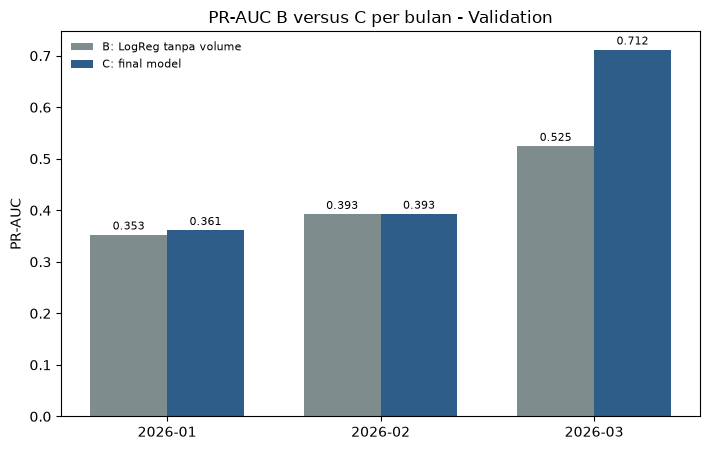

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))
x = np.arange(len(tabel_valid))
lebar = 0.36
ax.bar(x - lebar / 2, tabel_valid["PR-AUC B"], lebar, label="B: LogReg tanpa volume", color="#7f8c8d")
ax.bar(x + lebar / 2, tabel_valid["PR-AUC C"], lebar, label="C: final model", color="#2f5d8a")
ax.set_xticks(x)
ax.set_xticklabels(tabel_valid["bulan"])
ax.set_ylabel("PR-AUC")
ax.set_title("PR-AUC B versus C per bulan - Validation")
ax.legend(frameon=False, fontsize=8)
for i, nilai in enumerate(tabel_valid["PR-AUC B"]):
    ax.text(i - lebar / 2, nilai + 0.01, f"{nilai:.3f}", ha="center", fontsize=8)
for i, nilai in enumerate(tabel_valid["PR-AUC C"]):
    ax.text(i + lebar / 2, nilai + 0.01, f"{nilai:.3f}", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "10_post_test_pr_auc_b_c.png", dpi=160, bbox_inches="tight")
plt.show()

## Test final: paired bootstrap

Bootstrap berpasangan 1.000 kali pada test. Model C dihitung dari artefak final;
model B dihitung ulang dengan fit identik pada train, tanpa tuning.

In [4]:
referensi_test = pd.concat([train, valid, test], ignore_index=True)
test_lag = tambah_volume_lag(test, referensi_test)
X_test_C = siapkan_fitur(test_lag, metadata)
prob_C = model_final.predict_proba(X_test_C)[:, 1]
prob_B = model_B.predict_proba(test[["jam_pickup", "jarak_km", "jumlah_transit", "janji_hari", "berat_kg",
                                    "kota_tujuan", "layanan", "metode_bayar", "cuaca_saat_pickup"]])[:, 1]
y_test = test["terlambat"].to_numpy()

rng = np.random.default_rng(42)
pr_diff = []
cost_diff = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    yb = y_test[idx]
    pb = prob_B[idx]
    pc = prob_C[idx]
    pr_diff.append(average_precision_score(yb, pc) - average_precision_score(yb, pb))

    def biaya(proba, target, threshold):
        dikabari = proba >= threshold
        return int(((target == 1) & ~dikabari).sum()) * 50_000 + int(((target == 0) & dikabari).sum()) * 5_000

    mc = biaya(pc, yb, 0.09)
    me = int((yb == 0).sum()) * 5_000
    cost_diff.append(mc - me)

print("PR-AUC test B:", round(average_precision_score(y_test, prob_B), 4))
print("PR-AUC test C:", round(average_precision_score(y_test, prob_C), 4))
print("PR diff CI 95%:", [round(float(np.percentile(pr_diff, 2.5)), 4), round(float(np.percentile(pr_diff, 97.5)), 4)])
print("Cost diff CI 95%:", [int(np.percentile(cost_diff, 2.5)), int(np.percentile(cost_diff, 97.5))])

PR-AUC test B: 0.3601
PR-AUC test C: 0.3608
PR diff CI 95%: [-0.0073, 0.0086]
Cost diff CI 95%: [-7200000, -4580000]


## Ringkasan

- Gain lag fitur terkonsentrasi di Maret: Jan +0,0087, Feb +0,0005, Mar +0,1870.
- Pada test, PR-AUC C−B = 0,0007 dengan CI 95% [−0,0073; 0,0086], jadi tidak
  ada bukti peningkatan PR-AUC yang signifikan.
- Selisih biaya model−kabari semua pada test memiliki CI 95%
  [−Rp7.200.000; −Rp4.580.000], jadi model signifikan lebih murah.
- Model, fitur, threshold, dan config tidak diubah oleh notebook ini.